In [2]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
import matplotlib.pyplot as plt 
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

In [3]:
MIN_X, MAX_X = -1, 1
P_NATURE = np.random.random(size=6) * 2 - 1
P_NATURE[0] = 1

def nature(x: float, params: list[int] = P_NATURE):
    return np.poly1d(np.poly(params))(x)

def measure(x: float, error: float = 0):
    return nature(x) + error * np.random.normal(0, 1)


[[ 0.]
 [75.]]


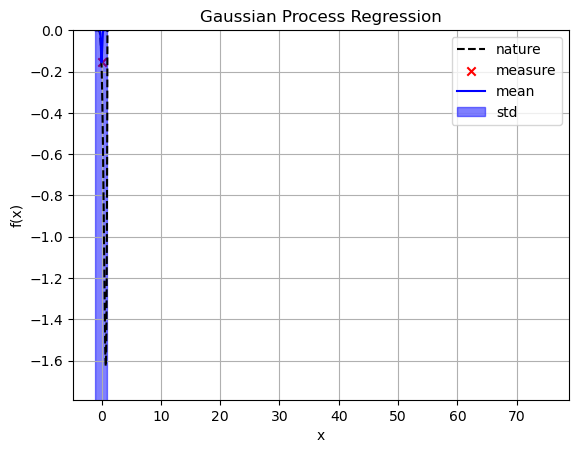

x=75.0, type(x)=<class 'float'>


TypeError: 'float' object is not iterable

In [ ]:
def plot(regressor: GaussianProcessRegressor, rng: tuple[float] = (MIN_X, MAX_X)):
    x = np.linspace(rng[0], rng[1], 1000)
    y = nature(x)
    plt.plot(x, y, label='nature', color='black', linestyle="dashed")
    plt.ylim([min(y) * 1.1, max(y) * 1.1])
    
    try: 
        x_train = regressor.X_train_
        if regressor.X_train_ is not None:
            print(regressor.X_train_)
            x_train = regressor.X_train_
            y_train = regressor.y_train_
            plt.scatter(x_train, y_train, label='measure', color='red', marker='x')
    except AttributeError:
        pass

    y_mean, y_std = regressor.predict(x.reshape(-1, 1), return_std=True)
    plt.plot(x, y_mean, label='mean', color='blue')
    plt.fill_between(x, y1=y_mean + y_std, y2=y_mean - y_std, label='std', color='blue', alpha=0.5)

    plt.title('Gaussian Process Regression')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.grid()
    plt.show()

def update_data(regressor: GaussianProcessRegressor, x: float, y: float):
    try:
        current_x = regressor.X_train_
    except AttributeError:
        current_x = None
    if current_x is not None:
        
        print(current_x.shape, x.shape)
        x = np.concatenate((current_x, x.reshape(-1, 1)))
    else:
        x = x.reshape(-1, 1)

    y = measure(x)
    if len(x) > 0:
        regressor.fit(x, y)
    return regressor

rbf = 1 * RBF(length_scale=0.1)
regressor = GaussianProcessRegressor(kernel=rbf, random_state=0)

n_init = 0
x = np.random.uniform(MIN_X, MAX_X, n_init)
y = measure(x)

if len(x) > 0:
    regressor.fit(x.reshape(-1, 1), y)

plot(regressor)

while True:
    try:
        x = float(input("x: "))
        if x < MIN_X or x > MAX_X:
            print(f"Please enter a number between {MIN_X} and {MAX_X}.")
            continue
        print(f"{x=}, {type(x)=}")
        y = measure(x)

        regressor = update_data(regressor, np.array([x]), np.array([y]))
        clear_output(wait=True)
        plot(regressor)
    except ValueError:
        print(f"{x=}, {type(x)=}")
        if list(x) == []:
            break
        print("Invalid input. Please enter a number.")
        continue